# 08 · Fielding Analytics

Catching percentages, run-outs and ground fielding for each player, with a look at how far small samples can be trusted.

Needs: numpy, pandas, matplotlib (`pip install -r notebooks/requirements.txt`).

> Running in Google Colab? Run this once in a new cell first (replace the URL with wherever your copy of the project lives), then run the notebook from the top:
> ```python
> !git clone https://github.com/YOUR-ACCOUNT/pitchvision.git   # or upload and unzip the project folder
> %cd pitchvision
> !pip install -q -r notebooks/requirements.txt
> ```

> About the data. The CSV files in `notebooks/data/` are synthetic: generated by `pitchvision/sample_data.py` with a fixed random seed. The players, matches and numbers are invented so the notebook can run straight away. They are not a real team's results. To use your own data, replace the CSV files with files that have the same columns (see `notebooks/data/DATA_DICTIONARY.md`).

In [1]:
# --- Setup: find the project folder so the shared `pitchvision` package can be imported ---
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "pitchvision").exists():        # the notebook is being run from notebooks/
    ROOT = ROOT.parent
if not (ROOT / "pitchvision").exists():
    raise RuntimeError("Cannot find the 'pitchvision' folder. Open this notebook from inside the PitchVision "
                       "project, or see the Google Colab instructions in notebooks/README.md.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "notebooks" / "data"             # sample CSV files (SYNTHETIC data)
EXPORTS = ROOT / "notebooks" / "exports"       # CSV files written by the notebooks
EXPORTS.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, GREEN, RED, YELLOW = "#0D1310", "#1F6B45", "#B3261E", "#F2C230"
print("Project folder:", ROOT)

Project folder: /Users/sahasreddy/Documents/Cricket


## 1. What is recorded

Fielding is recorded as events, each naming a player and what happened. Recording the misses matters as much as the successes, because a percentage needs both.

| Event | Meaning |
|---|---|
| catch / drop | a catch held or put down |
| run_out / direct_hit / missed_run_out | a run-out effected (a direct hit is one made by a throw that hit the stumps), or a chance missed |
| stumping / missed_stumping | wicket-keeper only |
| clean_stop / misfield | ground fielding |

$$\text{catch \%} = \frac{\text{catches}}{\text{catches}+\text{drops}}\times 100\qquad\text{ground fielding \%} = \frac{\text{clean stops}}{\text{clean stops}+\text{misfields}}\times 100$$

In [2]:
from pitchvision import stats

events = pd.read_csv(DATA / "fielding.csv", parse_dates=["date"])
print(len(events), "fielding events (SYNTHETIC)")
print(events["kind"].value_counts().to_string())

# Rows with a missing or unknown kind cannot be counted. Show how many there are, then drop them.
known = events[events["kind"].isin(stats.FIELDING_EVENTS)]
print("\nRows dropped for an unknown event type:", len(events) - len(known))

335 fielding events (SYNTHETIC)
kind
clean_stop        190
misfield           55
catch              39
drop               26
run_out            10
missed_run_out      8
direct_hit          7

Rows dropped for an unknown event type: 0


## 2. Player table

In [3]:
counts = known.pivot_table(index="player", columns="kind", values="count", aggfunc="sum", fill_value=0)
for col in stats.FIELDING_EVENTS:
    if col not in counts: counts[col] = 0
by_hand = pd.DataFrame({
    "catches": counts["catch"], "dropped": counts["drop"],
    "catch_pct": (counts["catch"] / (counts["catch"] + counts["drop"]) * 100).where((counts["catch"] + counts["drop"]) > 0),
    "run_outs": counts["run_out"] + counts["direct_hit"], "direct_hits": counts["direct_hit"],
    "ground_pct": (counts["clean_stop"] / (counts["clean_stop"] + counts["misfield"]) * 100).where((counts["clean_stop"] + counts["misfield"]) > 0),
})

career = pd.DataFrame(stats.career_fielding(known.to_dict("records"))).set_index("player")
for name in by_hand.index:                                       # the shared module must give the same numbers
    assert career.loc[name, "catch"] == by_hand.loc[name, "catches"]
    assert abs(career.loc[name, "catch_pct"] - by_hand.loc[name, "catch_pct"]) < 1e-9
by_hand.sort_values("catches", ascending=False).round(1)

,catches,dropped,catch_pct,run_outs,direct_hits,ground_pct
player,,,,,,
Imran Khan,7,2,77.8,3,1,94.1
Arun Mehta,5,0,100.0,0,0,86.7
Ben Carter,4,1,80.0,3,0,83.3
Omar Aziz,4,1,80.0,2,1,78.9
Dev Patel,3,0,100.0,1,1,81.8
Farhan Ali,3,0,100.0,0,0,91.7
Harry Singh,3,3,50.0,0,0,50.0
George Hill,2,2,50.0,1,0,100.0
Jack Wood,2,2,50.0,1,1,66.7


## 3. Catching

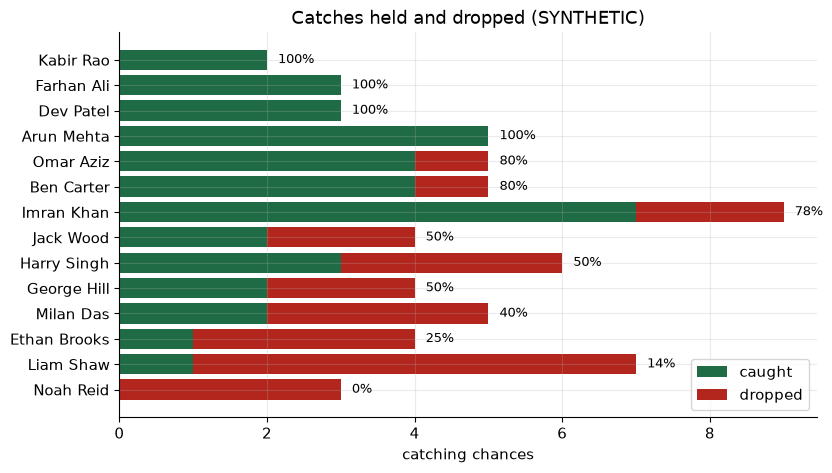

In [4]:
c = career.sort_values("catch_pct", ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(c.index, c["catch"], color=GREEN, label="caught")
ax.barh(c.index, c["drop"], left=c["catch"], color=RED, label="dropped")
for i, (name, row) in enumerate(c.iterrows()):
    ax.text(row["catch_chances"] + 0.15, i, f"{row['catch_pct']:.0f}%", va="center", fontsize=9)
ax.set_xlabel("catching chances"); ax.set_title("Catches held and dropped (SYNTHETIC)"); ax.legend(loc="lower right"); plt.show()

## 4. How much can a catch percentage be trusted?

A fielder who has held 3 of 4 has a 75% record, but four chances say very little. The Wilson interval gives a range the true rate plausibly lies in:

$$\frac{\hat p + \frac{z^2}{2n} \pm z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1+\frac{z^2}{n}},\qquad z = 1.96$$

Wide ranges that overlap mean the data cannot separate two fielders yet.

3 of 4 held  -> [30, 95] %
30 of 40 held -> [60, 86] %


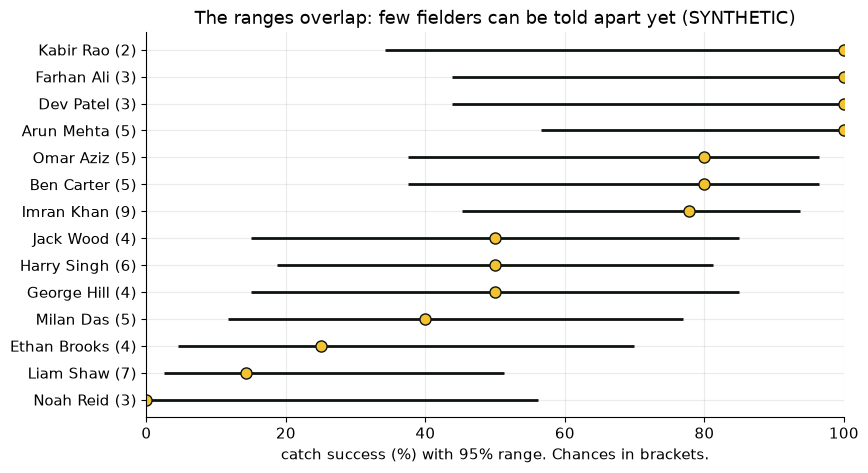

In [5]:
def wilson(successes, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = successes / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half) * 100, (centre + half) * 100

print("3 of 4 held  ->", [round(v) for v in wilson(3, 4)], "%")
print("30 of 40 held ->", [round(v) for v in wilson(30, 40)], "%")

c = career[career["catch_chances"] > 0].sort_values("catch_pct")
lows, highs = zip(*[wilson(r["catch"], r["catch_chances"]) for _, r in c.iterrows()])
fig, ax = plt.subplots(figsize=(9, 5))
ax.hlines(range(len(c)), lows, highs, color=INK, lw=2)
ax.plot(c["catch_pct"], range(len(c)), "o", color=YELLOW, mec=INK, ms=8)
ax.set_yticks(range(len(c))); ax.set_yticklabels([f"{n} ({int(r['catch_chances'])})" for n, r in c.iterrows()])
ax.set_xlabel("catch success (%) with 95% range. Chances in brackets."); ax.set_xlim(0, 100)
ax.set_title("The ranges overlap: few fielders can be told apart yet (SYNTHETIC)"); plt.show()

## 5. Run-outs and ground fielding

,run_out,direct_hit,missed_run_out,run_outs_total,run_out_pct
player,,,,,
Imran Khan,2,1,1,3,75.0
Ben Carter,3,0,1,3,75.0
Omar Aziz,1,1,0,2,100.0
Liam Shaw,1,1,0,2,100.0
Noah Reid,1,1,1,2,67.0
Dev Patel,0,1,0,1,100.0
George Hill,1,0,0,1,100.0
Jack Wood,0,1,2,1,33.0


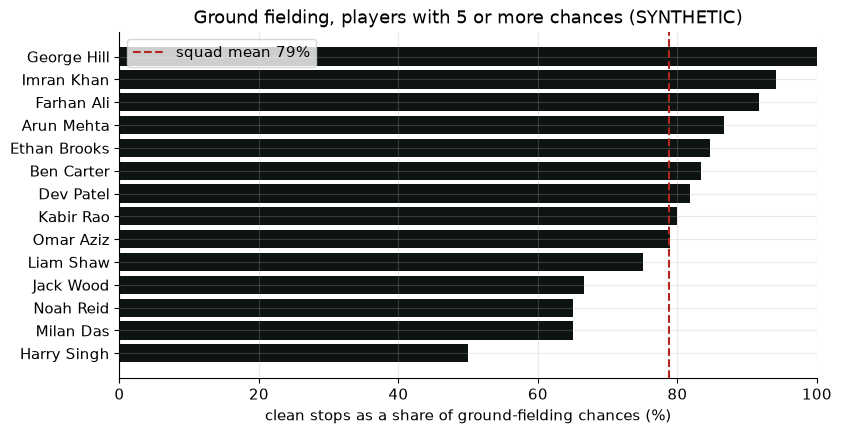

In [6]:
r = career[career["run_out_chances"] > 0].sort_values("run_outs_total", ascending=False)
display(r[["run_out", "direct_hit", "missed_run_out", "run_outs_total", "run_out_pct"]].round(0).head(8))

g = career[career["ground_chances"] >= 5].sort_values("ground_pct")
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(g.index, g["ground_pct"], color=INK)
ax.axvline(g["ground_pct"].mean(), color=RED, ls="--", label=f"squad mean {g['ground_pct'].mean():.0f}%")
ax.set_xlabel("clean stops as a share of ground-fielding chances (%)"); ax.set_xlim(0, 100); ax.legend()
ax.set_title("Ground fielding, players with 5 or more chances (SYNTHETIC)"); plt.show()

## 6. The team by match

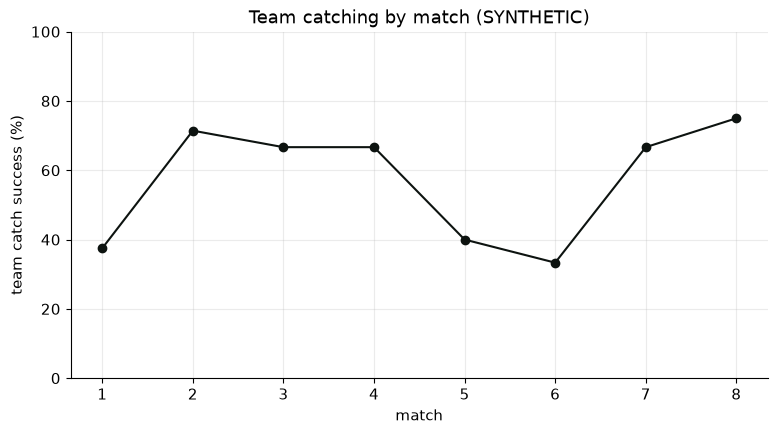

Season: 39 caught, 26 dropped, 60% (95% range 48 to 71%)


In [7]:
by_match = known.pivot_table(index="match_id", columns="kind", values="count", aggfunc="sum", fill_value=0)
by_match["catch_pct"] = by_match["catch"] / (by_match["catch"] + by_match["drop"]) * 100
fig, ax = plt.subplots()
ax.plot(by_match.index, by_match["catch_pct"], marker="o", color=INK)
ax.set_xlabel("match"); ax.set_ylabel("team catch success (%)"); ax.set_ylim(0, 100); ax.set_title("Team catching by match (SYNTHETIC)"); plt.show()
team_c, team_d = int(counts["catch"].sum()), int(counts["drop"].sum())
print(f"Season: {team_c} caught, {team_d} dropped, {team_c / (team_c + team_d) * 100:.0f}% (95% range {wilson(team_c, team_c + team_d)[0]:.0f} to {wilson(team_c, team_c + team_d)[1]:.0f}%)")
career.drop(columns=["name"], errors="ignore").round(1).to_csv(EXPORTS / "fielding_summary.csv")

## Summary

### Key findings
- Catch, run-out and ground-fielding percentages built with pandas match `stats.career_fielding`.
- With a handful of chances each, most fielders' 95% ranges overlap, so the table cannot rank them reliably.
- The team's season figure rests on far more chances and has a much narrower range.

### Interpretation
Fielding percentages become useful at team level first. For individuals, use them to start a conversation and to pick who needs more catching practice, and keep recording so the ranges narrow.

### Limitations
- A chance is a judgement call: was that a dropped catch or a half-chance?
- The record does not capture difficulty. A slip catch and a skier both count as one.
- Misses are under-recorded unless someone is assigned to note them.
- All figures shown come from synthetic data.

### How this notebook connects to the application
The Fielding Lab's Performance tracker saves each record through `POST /api/fielding/events` and shows this table from `stats.career_fielding`. Catching and fielding leaderboards in the Team Hub apply a minimum of three chances before ranking a catch percentage.